# Trials towards Smoothing Pitch Estimates

### To-Do
- come up with a quantifiable metric to asses the de-noising operation and how it affects downstream estimated values like up velocity & altiude
- Inculde Butterworth filtering
- see if other methods exist and try them
- handling the spikes and an explanation for why they are there
- settle on final values and produce corresponding metric and plots
- understand theoretical comparison between filter (usual metrics, lag, noise,...)

## Loading Data

In [1]:
import numpy as np
import matplotlib, matplotlib.pyplot as plt
from scipy.io import loadmat

In [2]:
Dataset = loadmat("sensor_data.mat")
print(Dataset.keys())

dict_keys(['__header__', '__version__', '__globals__', 'time_grid', 'high_end_imu', 'low_end_imu', 'odometer', 'reference_ins'])


In [3]:
time_grid = Dataset['time_grid'].flatten()
print(time_grid.shape)

(2496,)


In [4]:
num_epochs = len(time_grid.flatten())
num_epochs

2496

In [5]:
print(Dataset['high_end_imu'].dtype.names)
novatel_acc_data = Dataset['high_end_imu']['accelerometer'][0,0]
print(novatel_acc_data.shape)
novatel_gyro_data = Dataset['high_end_imu']['gyroscope'][0,0].flatten()
print(novatel_gyro_data.shape)

('accelerometer', 'gyroscope')
(2496, 3)
(2496,)


In [6]:
odom_speed = Dataset['odometer']['speed'][0,0].flatten()
print(odom_speed.shape)

(2496,)


In [7]:
ref_data = (
    Dataset['reference_ins']['altitude'][0, 0].flatten(),  
    np.radians(Dataset['reference_ins']['latitude'][0, 0].flatten()),  
    np.radians(Dataset['reference_ins']['longitude'][0, 0].flatten()),  
    Dataset['reference_ins']['velocity_east'][0, 0].flatten(),  
    Dataset['reference_ins']['velocity_north'][0, 0].flatten(),  
    Dataset['reference_ins']['velocity_up'][0, 0].flatten(),  
    np.radians(Dataset['reference_ins']['azimuth'][0, 0].flatten()),  
    np.radians(Dataset['reference_ins']['pitch'][0, 0].flatten()),  
    np.radians(Dataset['reference_ins']['roll'][0, 0].flatten())  
)

# Unpacking
ref_altitude, ref_latitude, ref_longitude, ref_ve, ref_vn, ref_vu, ref_az, ref_pitch, ref_roll = ref_data

## Compute Pitch with Pre-filtering

In [8]:
def extract_sensor_data(e, novatel_acc_data, novatel_gyro_data, odom_speed):
    """Extract sensor data for current epoch."""
    return (
        novatel_acc_data[e, 0], 
        -1 * novatel_acc_data[e, 1], 
        novatel_acc_data[e, 2], 
        novatel_gyro_data[e], 
        odom_speed[e]
    )

### Exponential Moving Avergae (EMA)

In [9]:
def compute_attitude_ema(e, fx, fy, fz, omega_z, v_od, odom_speed, filtered_speed, roll_est, pitch_est, alpha=0.1):
    """Calculate pitch and roll angles using filtered acceleration from EMA."""
    
    # Step 1: Compute filtered speed for current epoch using EMA
    filtered_speed[e] = alpha * odom_speed[e] + (1 - alpha) * filtered_speed[e-1]
    
    # Step 2: Compute acceleration using filtered speeds
    a_od = filtered_speed[e] - filtered_speed[e-1]
    
    # Step 3: Update roll and pitch estimates
    roll_est[e] = np.arctan2(-(fx + v_od * omega_z), fz)
    pitch_est[e] = np.arctan2(-(fy - a_od), np.sqrt(fx**2 + fz**2))


In [84]:
def run_epochs_ema(num_epochs, ref_pitch, ref_roll, odom_speed, novatel_acc_data, novatel_gyro_data, alpha):
    # Initialize arrays
    pitch_est = np.zeros(num_epochs)
    roll_est = np.zeros(num_epochs)
    filtered_speed = np.zeros(num_epochs)
    
    # Set initial values
    pitch_est[0] = ref_pitch[0]
    roll_est[0] = ref_roll[0]
    filtered_speed[0] = odom_speed[0]
    
    # Loop through epochs
    for e in range(1, num_epochs):
        fx, fy, fz, omega_z, v_od = extract_sensor_data(e, novatel_acc_data, novatel_gyro_data, odom_speed)
        compute_attitude_ema(e, fx, fy, fz, omega_z, v_od, odom_speed, filtered_speed, roll_est, pitch_est, alpha)
    
    return pitch_est

In [85]:
# Alpha values to experiment with
alpha_values = [0.1,0.3, 1]

# Store pitch estimates for each alpha
pitch_estimates = []

# Run epochs for each alpha value and collect results
for alpha in alpha_values:
    pitch_est = run_epochs_ema(num_epochs, ref_pitch, ref_roll, odom_speed, novatel_acc_data, novatel_gyro_data, alpha)
    pitch_estimates.append(pitch_est)

In [86]:
# Calculate SNR for each alpha
snr_values = [10 * np.log10(np.mean(ref_pitch**2) / np.mean((pitch_est - ref_pitch)**2))
              for pitch_est in pitch_estimates]

# Display SNR values
for i, alpha in enumerate(alpha_values):
    print(f"SNR for alpha = {alpha}: {snr_values[i]:.2f} dB")


SNR for alpha = 0.1: -10.11 dB
SNR for alpha = 0.3: -9.25 dB
SNR for alpha = 1: -8.19 dB


In [12]:
# Calculate MSE between pitch estimates and reference pitch
mse_values = [np.mean((pitch_est - ref_pitch)**2) for pitch_est in pitch_estimates]

# Print MSE values for each alpha
for i, alpha in enumerate(alpha_values):
    print(f"MSE for alpha = {alpha}: {mse_values[i]}")


MSE for alpha = 0.1: 0.007379406302553462
MSE for alpha = 0.3: 0.006062841771682765
MSE for alpha = 1: 0.0047446931174720125


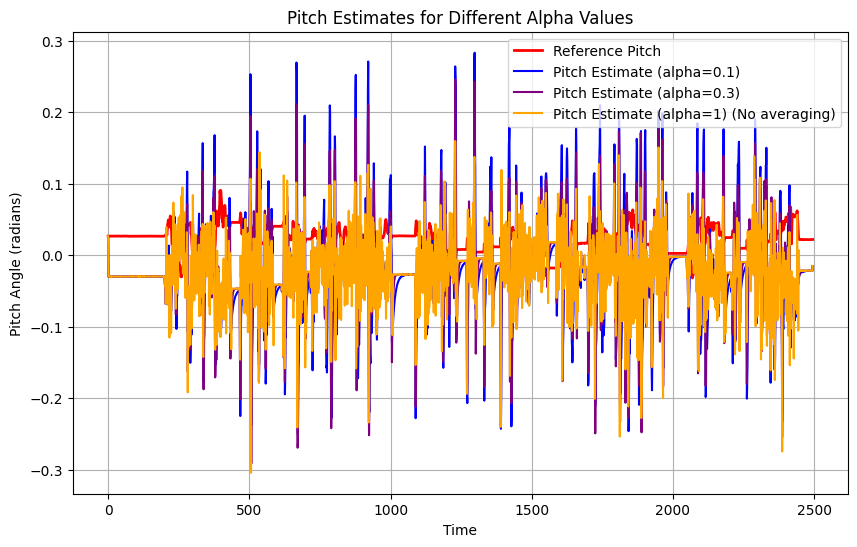

In [13]:
# Plotting the results
plt.figure(figsize=(10, 6))

# Plot the reference pitch for comparison
plt.plot(time_grid, ref_pitch, label="Reference Pitch", linestyle='-', color='r', linewidth=2)

# Plot pitch estimates for different alpha values
colors = ['b', 'purple', 'orange', 'g']
for i, alpha in enumerate(alpha_values):
    label = f"Pitch Estimate (alpha={alpha})"
    if alpha == 1.0:
        label += " (No averaging)"
    plt.plot(time_grid, pitch_estimates[i], label=label, linestyle='-', color=colors[i])

# Labels and title
plt.xlabel("Time")
plt.ylabel("Pitch Angle (radians)")
plt.title("Pitch Estimates for Different Alpha Values")

# Legend
plt.legend()

# Grid for better visualization
plt.grid(True)

# Show the plot
plt.show()

### Moving Average (MA)

In [14]:
from collections import deque

def compute_attitude_ma(e, fx, fy, fz, omega_z, v_od, odom_speed, filtered_speed, roll_est, pitch_est, window_size=3):
    """Calculate pitch and roll angles using filtered acceleration from Moving Average."""
    
    # Initialize sliding window for moving average (only do this for the first epoch)
    if e == 1:
        global speed_window  # Use a global variable to maintain the window state
        speed_window = deque([odom_speed[0]], maxlen=window_size)

    # Step 1: Update the moving average window
    speed_window.append(odom_speed[e])
    
    # Step 2: Compute the filtered speed as the average of the window
    filtered_speed[e] = sum(speed_window) / len(speed_window)
    
    # Step 3: Compute acceleration using filtered speeds
    a_od = filtered_speed[e] - filtered_speed[e-1]
    
    # Step 4: Update roll and pitch estimates
    roll_est[e] = np.arctan2(-(fx + v_od * omega_z), fz)
    pitch_est[e] = np.arctan2(-(fy - a_od), np.sqrt(fx**2 + fz**2))


In [15]:
def run_epochs_ma(num_epochs, ref_pitch, ref_roll, odom_speed, novatel_acc_data, novatel_gyro_data, window_size):
    # Initialize arrays
    pitch_est = np.zeros(num_epochs)
    roll_est = np.zeros(num_epochs)
    filtered_speed = np.zeros(num_epochs)
    
    # Set initial values
    pitch_est[0] = ref_pitch[0]
    roll_est[0] = ref_roll[0]
    filtered_speed[0] = odom_speed[0]
    
    # Loop through epochs
    for e in range(1, num_epochs):
        fx, fy, fz, omega_z, v_od = extract_sensor_data(e, novatel_acc_data, novatel_gyro_data, odom_speed)
        compute_attitude_ma(e, fx, fy, fz, omega_z, v_od, odom_speed, filtered_speed, roll_est, pitch_est, window_size)
    
    return pitch_est

In [87]:
# Moving average window sizes to experiment with
window_sizes = [1,3,5]  # Adjust as needed for experimentation

# Store pitch estimates for each window size
pitch_estimates = []

# Run epochs for each window size and collect results
for window_size in window_sizes:
    pitch_est = run_epochs_ma(num_epochs, ref_pitch, ref_roll, odom_speed, novatel_acc_data, novatel_gyro_data, window_size)
    pitch_estimates.append(pitch_est)

In [88]:
# Calculate SNR for each window size
snr_values_ma = [
    10 * np.log10(np.mean(ref_pitch**2) / np.mean((pitch_est - ref_pitch)**2))
    for pitch_est in pitch_estimates
]

# Display SNR values
for i, window_size in enumerate(window_sizes):
    print(f"SNR for window size = {window_size}: {snr_values_ma[i]:.2f} dB")


SNR for window size = 1: -8.19 dB
SNR for window size = 3: -9.00 dB
SNR for window size = 5: -9.77 dB


In [31]:
# Calculate MSE between pitch estimates and reference pitch
mse_values = [np.mean((pitch_est - ref_pitch)**2) for pitch_est in pitch_estimates]

# Print MSE values for each alpha
for i, w in enumerate(window_sizes):
    print(f"MSE for window size = {w}: {mse_values[i]}")

MSE for window size = 1: 0.0047446931174720125
MSE for window size = 3: 0.005720827538986972
MSE for window size = 5: 0.006825552032910345


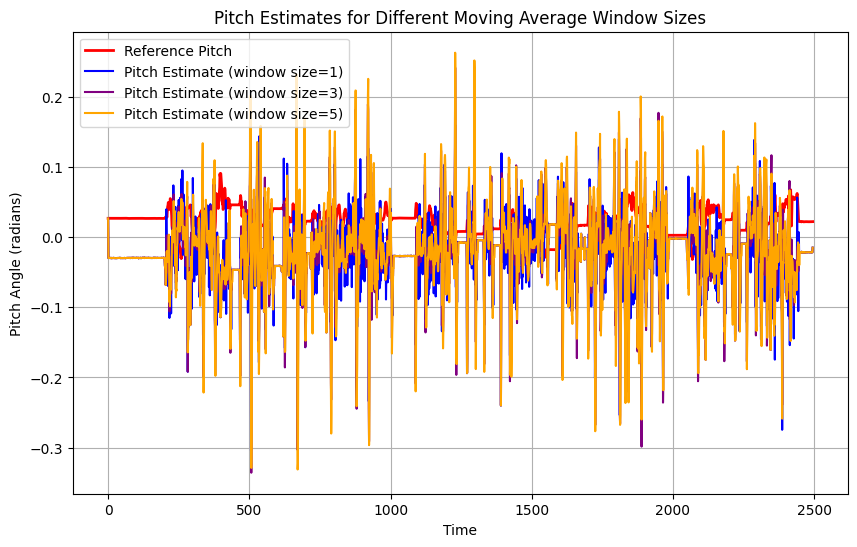

In [17]:
# Plotting the results
plt.figure(figsize=(10, 6))

# Plot the reference pitch for comparison
plt.plot(time_grid, ref_pitch, label="Reference Pitch", linestyle='-', color='r', linewidth=2)

# Plot pitch estimates for different window sizes
colors = ['b', 'purple', 'orange', 'g']
for i, window_size in enumerate(window_sizes):
    label = f"Pitch Estimate (window size={window_size})"
    plt.plot(time_grid, pitch_estimates[i], label=label, linestyle='-', color=colors[i])

# Labels and title
plt.xlabel("Time")
plt.ylabel("Pitch Angle (radians)")
plt.title("Pitch Estimates for Different Moving Average Window Sizes")

# Legend
plt.legend()

# Grid for better visualization
plt.grid(True)

# Show the plot
plt.show()

### Butterworth Filtering

In [18]:
from scipy.signal import butter

In [19]:
# Function to compute Butterworth filter coefficients (once before running epochs)
def initialize_butterworth_filter(cutoff=0.2, fs=1.0, order=1):
    nyquist = 0.5 * fs
    normal_cutoff = cutoff / nyquist
    b, a = butter(order, normal_cutoff, btype='low', analog=False)
    return b, a

In [20]:
def compute_attitude_butterworth(e, fx, fy, fz, omega_z, v_od, odom_speed, filtered_speed, roll_est, pitch_est, b, a):
    """Calculate pitch and roll angles using filtered acceleration from the Butterworth filter."""
    
    # Step 1: Apply recursive Butterworth filtering using current and previous values
    filtered_speed[e] = b[0] * odom_speed[e] + b[1] * odom_speed[e-1] - a[1] * filtered_speed[e-1]
    
    # Step 2: Compute acceleration using filtered speeds
    a_od = filtered_speed[e] - filtered_speed[e-1]
    
    # Step 3: Update roll and pitch estimates
    roll_est[e] = np.arctan2(-(fx + v_od * omega_z), fz)
    pitch_est[e] = np.arctan2(-(fy - a_od), np.sqrt(fx**2 + fz**2))

In [21]:
def run_epochs_butterworth(num_epochs, ref_pitch, ref_roll, odom_speed, novatel_acc_data, novatel_gyro_data, cutoff, order):
    # Initialize arrays
    pitch_est = np.zeros(num_epochs)
    roll_est = np.zeros(num_epochs)
    filtered_speed = np.zeros(num_epochs)
    
    # Set initial values
    pitch_est[0] = ref_pitch[0]
    roll_est[0] = ref_roll[0]
    filtered_speed[0] = odom_speed[0]
    
    # Step 1: Initialize Butterworth filter coefficients
    b, a = initialize_butterworth_filter(cutoff=cutoff, fs=1.0, order=order)
    
    # Loop through epochs
    for e in range(1, num_epochs):
        fx, fy, fz, omega_z, v_od = extract_sensor_data(e, novatel_acc_data, novatel_gyro_data, odom_speed)
        compute_attitude_butterworth(e, fx, fy, fz, omega_z, v_od, odom_speed, filtered_speed, roll_est, pitch_est, b, a)
    
    return pitch_est

In [89]:
# Butterworth filter parameters to experiment with
cutoff_frequencies = [0.2]  # Adjust to find optimal performance
filter_orders = [1, 2, 3]  # Test first-order and second-order filters

# Store pitch estimates for each parameter configuration
pitch_estimates = []

# Run epochs for each cutoff frequency and order combination
for order in filter_orders:
    for cutoff in cutoff_frequencies:
        pitch_est = run_epochs_butterworth(num_epochs, ref_pitch, ref_roll, odom_speed, 
                                           novatel_acc_data, novatel_gyro_data, cutoff, order)
        pitch_estimates.append((cutoff, order, pitch_est))

In [90]:
# Calculate SNR for each combination of cutoff frequency and filter order
snr_values_butterworth = [
    (cutoff, order, 10 * np.log10(np.mean(ref_pitch**2) / np.mean((pitch_est - ref_pitch)**2)))
    for cutoff, order, pitch_est in pitch_estimates
]

# Display SNR values
for cutoff, order, snr in snr_values_butterworth:
    print(f"SNR for cutoff = {cutoff} Hz, order = {order}: {snr:.2f} dB")


SNR for cutoff = 0.2 Hz, order = 1: -8.64 dB
SNR for cutoff = 0.2 Hz, order = 2: -9.20 dB
SNR for cutoff = 0.2 Hz, order = 3: -9.64 dB


In [91]:
# Clip pitch estimates to the range [-0.1, 0.1]
pitch_estimates_clipped = [
    (cutoff, order, np.clip(pitch_est, -0.1, 0.1)) for cutoff, order, pitch_est in pitch_estimates
]

In [92]:
# Calculate SNR for each combination of cutoff frequency and filter order
snr_values_butterworth = [
    (cutoff, order, 10 * np.log10(np.mean(ref_pitch**2) / np.mean((pitch_est - ref_pitch)**2)))
    for cutoff, order, pitch_est in pitch_estimates_clipped
]

# Display SNR values
for cutoff, order, snr in snr_values_butterworth:
    print(f"SNR for cutoff = {cutoff} Hz, order = {order}: {snr:.2f} dB")

SNR for cutoff = 0.2 Hz, order = 1: -7.60 dB
SNR for cutoff = 0.2 Hz, order = 2: -7.87 dB
SNR for cutoff = 0.2 Hz, order = 3: -8.17 dB


In [65]:
# Calculate MSE between Butterworth pitch estimates and reference pitch
mse_values_butterworth = [
    (cutoff, order, np.mean((pitch_est - ref_pitch)**2))
    for cutoff, order, pitch_est in pitch_estimates_clipped
]

# Display MSE values
for cutoff, order, mse in mse_values_butterworth:
    print(f"MSE for cutoff = {cutoff} Hz, order = {order}: {mse}")


MSE for cutoff = 0.2 Hz, order = 1: 0.00413977696216322
MSE for cutoff = 0.2 Hz, order = 2: 0.0044095068945884846
MSE for cutoff = 0.2 Hz, order = 3: 0.004728499529453551


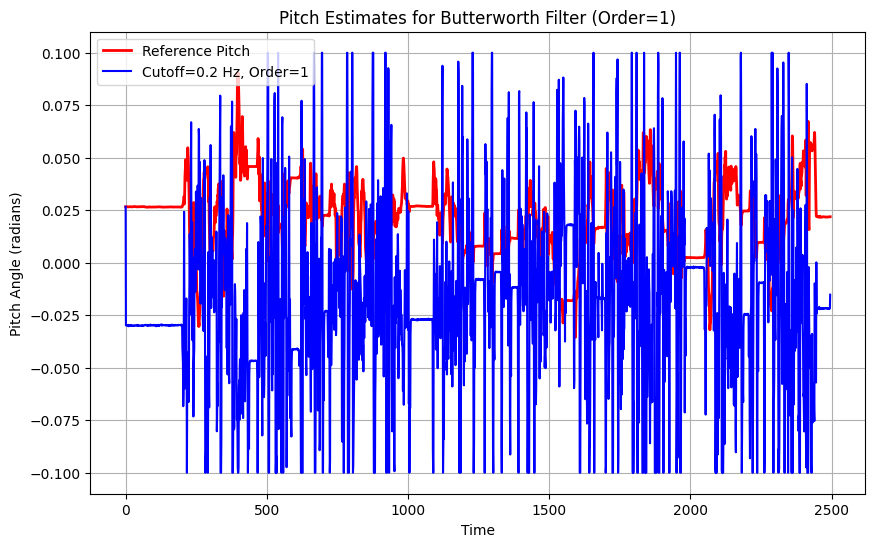

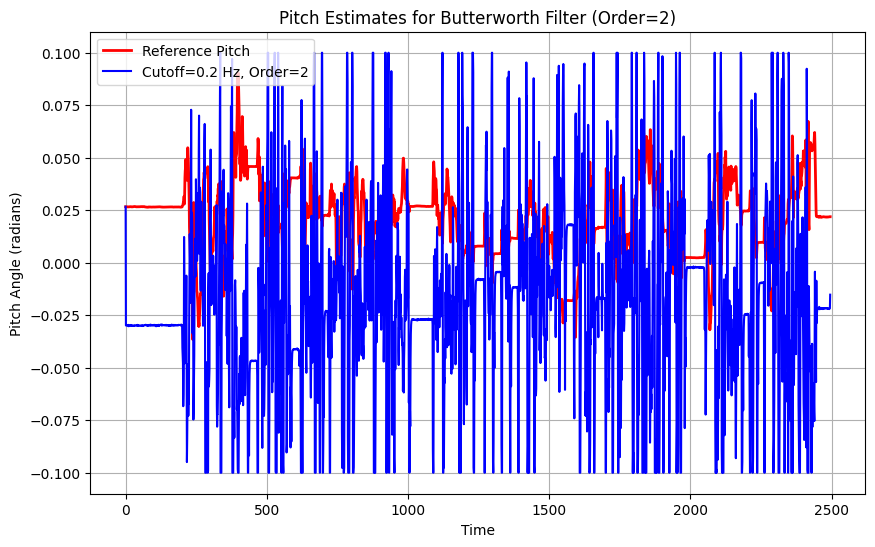

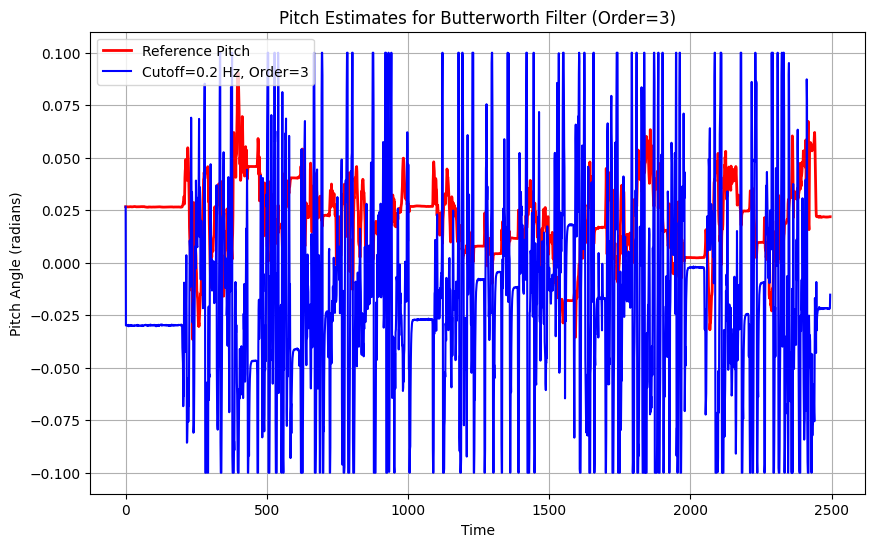

In [66]:
colors = ['b', 'purple', 'orange']  # Colors for different cutoff frequencies

# Plotting for each filter order
for i, order in enumerate(filter_orders):
    plt.figure(figsize=(10, 6))
    
    # Plot the reference pitch
    plt.plot(time_grid, ref_pitch, label="Reference Pitch", linestyle='-', color='r', linewidth=2)
    
    # Plot the pitch estimates for each cutoff frequency at this filter order
    for j, cutoff in enumerate(cutoff_frequencies):
        k = (len(cutoff_frequencies)*i) + j
        label = f"Cutoff={pitch_estimates_clipped[k][0]} Hz, Order={pitch_estimates_clipped[k][1]}"
        plt.plot(time_grid, pitch_estimates_clipped[k][2], label=label, linestyle='-', color=colors[j % len(colors)])
    
    # Labels and title
    plt.xlabel("Time")
    plt.ylabel("Pitch Angle (radians)")
    plt.title(f"Pitch Estimates for Butterworth Filter (Order={order})")
    
    # Legend
    plt.legend()
    
    # Grid for better visualization
    plt.grid(True)
    
    # Show the plot
    plt.show()

### Tustin’s Approximation (Bilinear Transformation)

In [24]:
def compute_attitude_tustin(e, fx, fy, fz, omega_z, v_od, odom_speed, filtered_speed, roll_est, pitch_est, beta=0.9):
    """Calculate pitch and roll angles using filtered acceleration from Tustin's approximation."""
    
    # Step 1: Apply Tustin's approximation to compute acceleration
    a_od = 2 * ((odom_speed[e] - odom_speed[e-1]) / (1 + beta))
    
    # Step 3: Update roll and pitch estimates
    roll_est[e] = np.arctan2(-(fx + v_od * omega_z), fz)
    pitch_est[e] = np.arctan2(-(fy - a_od), np.sqrt(fx**2 + fz**2))


In [25]:
def run_epochs_tustin(num_epochs, ref_pitch, ref_roll, odom_speed, novatel_acc_data, novatel_gyro_data, beta):
    # Initialize arrays
    pitch_est = np.zeros(num_epochs)
    roll_est = np.zeros(num_epochs)
    filtered_speed = np.zeros(num_epochs)
    
    # Set initial values
    pitch_est[0] = ref_pitch[0]
    roll_est[0] = ref_roll[0]
    filtered_speed[0] = odom_speed[0]
    
    # Loop through epochs
    for e in range(1, num_epochs):
        fx, fy, fz, omega_z, v_od = extract_sensor_data(e, novatel_acc_data, novatel_gyro_data, odom_speed)
        compute_attitude_tustin(e, fx, fy, fz, omega_z, v_od, odom_speed, filtered_speed, roll_est, pitch_est, beta)
    
    return pitch_est


In [97]:
# Define beta values to test
beta_values = [0.9]

# Store pitch estimates for each beta value
pitch_estimates_tustin = []

# Run epochs for each beta value and collect results
for beta in beta_values:
    pitch_est = run_epochs_tustin(num_epochs, ref_pitch, ref_roll, odom_speed, novatel_acc_data, novatel_gyro_data, beta)
    pitch_estimates_tustin.append(pitch_est)


In [98]:
# Calculate SNR for each beta value
snr_values_tustin = [
    10 * np.log10(np.mean(ref_pitch**2) / np.mean((pitch_est - ref_pitch)**2))
    for pitch_est in pitch_estimates_tustin
]

# Display SNR values
for i, beta in enumerate(beta_values):
    print(f"SNR for beta = {beta}: {snr_values_tustin[i]:.2f} dB")


SNR for beta = 0.9: -8.26 dB


In [99]:
# Clip pitch estimates to the range [-0.1, 0.1]
pitch_estimates_tustin_clipped = [np.clip(pitch_est, -0.1, 0.1) for pitch_est in pitch_estimates_tustin]

In [100]:
# Calculate SNR for each beta value
snr_values_tustin = [
    10 * np.log10(np.mean(ref_pitch**2) / np.mean((pitch_est - ref_pitch)**2))
    for pitch_est in pitch_estimates_tustin_clipped
]

# Display SNR values
for i, beta in enumerate(beta_values):
    print(f"SNR for beta = {beta}: {snr_values_tustin[i]:.2f} dB")

SNR for beta = 0.9: -7.58 dB


In [59]:
# Calculate MSE between Tustin pitch estimates and reference pitch
mse_values_tustin = [
    (beta, np.mean((pitch_est - ref_pitch)**2))
    for beta, pitch_est in zip(beta_values, pitch_estimates_tustin_clipped)
]

# Display MSE values
for beta, mse in mse_values_tustin:
    print(f"MSE for beta = {beta}: {mse}")


MSE for beta = 0.9: 0.004128509180697228


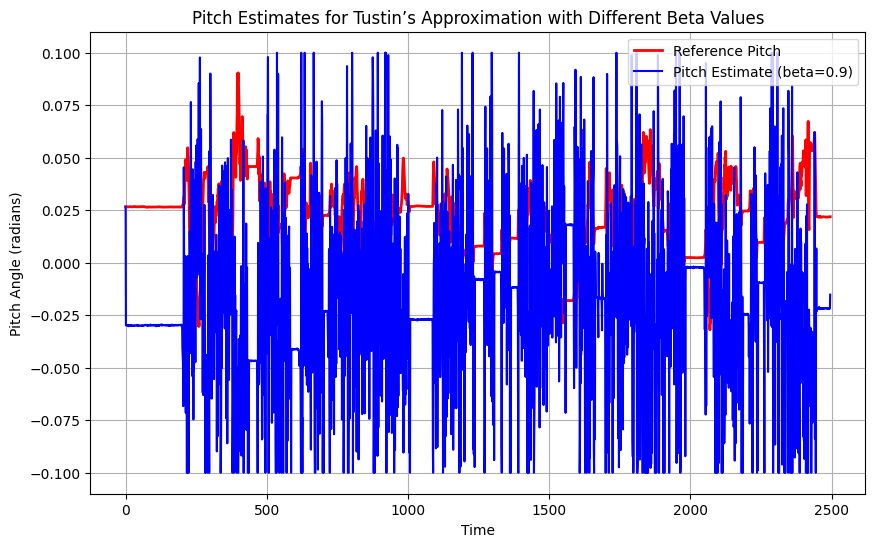

In [61]:
# Plotting the results
plt.figure(figsize=(10, 6))

# Plot the reference pitch for comparison
plt.plot(time_grid, ref_pitch, label="Reference Pitch", linestyle='-', color='r', linewidth=2)

# Plot pitch estimates for different beta values
colors = ['b', 'g', 'orange']
for i, beta in enumerate(beta_values):
    label = f"Pitch Estimate (beta={beta})"
    plt.plot(time_grid, pitch_estimates_tustin_clipped[i], label=label, linestyle='-', color=colors[i])

# Labels and title
plt.xlabel("Time")
plt.ylabel("Pitch Angle (radians)")
plt.title("Pitch Estimates for Tustin’s Approximation with Different Beta Values")

# Legend
plt.legend()

# Grid for better visualization
plt.grid(True)

# Show the plot
plt.show()

### Butterworth + Tustin's Approximation

In [68]:
def compute_attitude_BT(e, fx, fy, fz, omega_z, v_od, odom_speed, filtered_speed, roll_est, pitch_est, b, a, beta):
    """Calculate pitch and roll angles using filtered acceleration from the Butterworth filter."""
    
    # Step 1: Apply recursive Butterworth filtering using current and previous values
    filtered_speed[e] = b[0] * odom_speed[e] + b[1] * odom_speed[e-1] - a[1] * filtered_speed[e-1]
    
    # Step 2: Compute acceleration using filtered speeds
    a_od = 2 * ((filtered_speed[e] - filtered_speed[e-1]) / (1 + beta))
    
    # Step 3: Update roll and pitch estimates
    roll_est[e] = np.arctan2(-(fx + v_od * omega_z), fz)
    pitch_est[e] = np.arctan2(-(fy - a_od), np.sqrt(fx**2 + fz**2))

In [69]:
def run_epochs_BT(num_epochs, ref_pitch, ref_roll, odom_speed, novatel_acc_data, novatel_gyro_data, cutoff, order, beta):
    # Initialize arrays for pitch, roll, and filtered speed
    pitch_est = np.zeros(num_epochs)
    roll_est = np.zeros(num_epochs)
    filtered_speed = np.zeros(num_epochs)
    
    # Set initial values
    pitch_est[0] = ref_pitch[0]
    roll_est[0] = ref_roll[0]
    filtered_speed[0] = odom_speed[0]
    
    # Initialize Butterworth filter coefficients
    b, a = initialize_butterworth_filter(cutoff=cutoff, fs=1.0, order=order)
    
    # Loop through epochs
    for e in range(1, num_epochs):
        fx, fy, fz, omega_z, v_od = extract_sensor_data(e, novatel_acc_data, novatel_gyro_data, odom_speed)
        compute_attitude_BT(e, fx, fy, fz, omega_z, v_od, odom_speed, filtered_speed, roll_est, pitch_est, b, a, beta)
    
    return pitch_est

In [79]:
# Parameters for Butterworth + Tustin simulation
cutoff_frequency = 0.1  # Hz
filter_order = 1  # Second-order Butterworth filter
beta_value = 0.9  # Smoothing parameter for Tustin’s approximation

# Run the simulation
pitch_estimate_BT = run_epochs_BT(num_epochs, ref_pitch, ref_roll, odom_speed, 
                                  novatel_acc_data, novatel_gyro_data, 
                                  cutoff_frequency, filter_order, beta_value)

pitch_estimate_BT_clipped = np.clip(pitch_estimate_BT, -0.1, 0.1)

In [82]:
# Compute the signal-to-noise ratio (SNR)
signal_power = np.mean(ref_pitch**2)  # Power of the reference pitch (signal)
noise_power = np.mean((pitch_estimate_BT_clipped - ref_pitch)**2)  # Power of the noise (error)

# Calculate SNR in decibels (dB)
snr_db = 10 * np.log10(signal_power / noise_power)
print(f"SNR: {snr_db} dB")


SNR: -7.937531794039868 dB


In [80]:
print(np.mean((pitch_estimate_BT_clipped - ref_pitch)**2))

0.004477688715657582


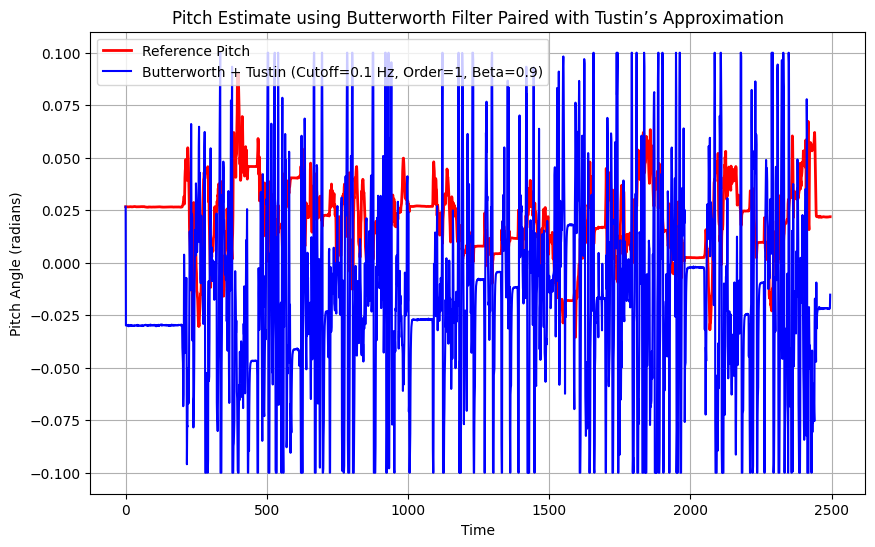

In [81]:
# Plotting the results
plt.figure(figsize=(10, 6))

# Plot the reference pitch for comparison
plt.plot(time_grid, ref_pitch, label="Reference Pitch", linestyle='-', color='r', linewidth=2)

# Plot the pitch estimate
plt.plot(time_grid, pitch_estimate_BT_clipped, label=f"Butterworth + Tustin (Cutoff={cutoff_frequency} Hz, Order={filter_order}, Beta={beta_value})", 
         linestyle='-', color='b')

# Labels and title
plt.xlabel("Time")
plt.ylabel("Pitch Angle (radians)")
plt.title("Pitch Estimate using Butterworth Filter Paired with Tustin’s Approximation")

# Legend
plt.legend()

# Grid for better visualization
plt.grid(True)

# Show the plot
plt.show()